# FloodNet — YOLO11n-seg sobre la misma partición

Cuaderno de comparación. Entrena **YOLO11n-seg** (Ultralytics) con exactamente las mismas 1.387 / 434 / 426
imágenes de train / val / test que el U-Net híbrido de `floodnet-segmentation.ipynb`: el dataset
FloodNet-Supervised v1.0 completo, con su reparto oficial. Lo evalúa con
la misma métrica semántica (mIoU por acumulación de matriz de confusión) y deja el modelo exportado a
**ONNX** para medir después la inferencia en el mismo equipo.

## El problema de fondo: FloodNet no es un dataset de instancias

YOLO-seg es un modelo de **segmentación de instancias**: detecta objetos (caja + clase) y da una
máscara por objeto. FloodNet es **segmentación semántica**: cada píxel tiene una clase y
no hay objetos. Hierba, árboles, agua y carreteras son *regiones*, no cosas contables.

Para poder entrenar YOLO se hace lo único razonable: **cada componente conexa de cada clase se
trata como una instancia** y su contorno se convierte en polígono. Eso tiene consecuencias que el
cuaderno mide en vez de suponer:

| Aspecto | Efecto |
|---|---|
| Clases *objeto* (edificios, vehículos, piscinas) | Encajan bien: regiones compactas y separadas. |
| Clases *región* (Grass, Tree, Road, Water) | Encajan mal: regiones enormes, con huecos y fragmentadas. |
| Huecos | Un polígono YOLO no tiene huecos. Los que contienen otra clase se resuelven por orden de pintado; los de *Background* se abren en el polígono (sección 3). |
| Resolución de máscara | YOLO predice prototipos a 1/4 (128×128 para 512): bordes más bastos. |
| Salida | Instancias, no un mapa por píxel. Hay que **repintarlas** en un mapa semántico. |
| *Background* | No es una clase de YOLO: es lo que no cubre ninguna instancia (ver abajo). |

**Por qué *Background* no se entrena como clase.** YOLO ya tiene un fondo implícito: lo que no es
ninguna instancia. Es la fila y la columna `background` que Ultralytics añade a su matriz de confusión.
Si además se entrena la clase 0 de FloodNet, hay dos fondos distintos con casi el mismo nombre, y el
modelo tiene que aprender como "objeto" algo que por definición es *lo que no es nada de lo demás*.
Por eso YOLO se entrena con las **9 clases restantes** y, al repintar, **los píxeles que no cubre
ninguna instancia se asignan a *Background***. La evaluación sigue siendo sobre las 10 clases, igual
que la del U-Net y DeepLabV3+.

Tiene un coste, que las **Conclusiones** miden: el modelo no aprende a dejar sin cubrir las zonas de
*Background* y su IoU cae de 0.394 a 0.036 frente a la ejecución en la que era una clase más.

## Índice

| Sección | Contenido |
|---|---|
| **P** | Parámetros del experimento (todo lo configurable, en un sitio) |
| **0** | Entorno |
| **1** | Datos y partición (idéntica al cuaderno principal) |
| **2** | ¿Cuántas "instancias" hay? Análisis de componentes conexas |
| **3** | Conversión máscara → polígonos YOLO |
| **4** | Prueba de ida y vuelta: el techo que impone la conversión |
| **5** | Entrenamiento |
| **6** | Evaluación: mAP de instancias y mIoU semántico |
| **7** | Exportación a ONNX y verificación |

---
# P. Parámetros del experimento

**Todas las decisiones configurables están en esta celda.** Se imprimen aquí y se guardan, junto con
la lista de imágenes de cada partición y los resultados, en `models/yolo11n_seg_floodnet_config.json`,
al lado del `.onnx`. Así cualquier cifra del cuaderno se puede rastrear y replicar.

Sobre la resolución: **se entrena a 512×512**, la misma entrada que el U-Net híbrido. Se reutiliza
la caché `data/cache512_full` y la comparación es de igual a igual. Una resolución mayor favorecería a
*Vehicle* y a las máscaras a 1/4 de YOLO, pero obligaría a regenerar la caché y la comparación
dejaría de ser directa.

In [1]:
import json
import os
import random
import re
import shutil
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from tqdm.auto import tqdm

CONFIG = {
    "experimento": "yolo11n-seg_floodnet_full_512",
    # --- datos y partición (idénticos a floodnet-segmentation.ipynb) ---
    "dataset": "FloodNet-Supervised_v1.0 (2343 imágenes con máscara)",
    "img_size": 512,                    # entrada del modelo = tamaño de la caché
    "seed": 42,                         # entrenamiento (el split es el oficial)
    "mascaras_reparadas": "data_finally sustituye a la máscara oficial en las 398 que corrige",
    "excluir_una_clase": True,          # fuera las máscaras de una sola clase sin corrección
    "split": {
        "train": "train oficial sin máscaras de una sola clase (1387)",
        "val":   "val oficial sin máscaras de una sola clase (434)",
        "test":  "test oficial sin máscaras de una sola clase (426)",
    },
    # --- conversión máscara -> polígonos (sección 3) ---
    "min_area_px": 20,                  # componentes más pequeñas se descartan (ruido de anotación)
    "poly_eps_px": 1.0,                 # tolerancia de cv2.approxPolyDP
    "clases_yolo": "9: todas menos Background (índice YOLO = índice FloodNet - 1)",
    "huecos": "se abren los de >= min_area_px con >= min_area_px de Background dentro",
    # --- entrenamiento (Ultralytics) ---
    "modelo_base": "yolo11n-seg.pt",    # preentrenado en COCO
    "epochs": 300,                      # ~4,4 veces más lotes por época que con 317 imágenes
    "patience": 50,                     # early stopping sobre fitness de val
    "batch": 16,
    "workers": 4,                       # con 0 cada época tarda ~6 veces más; si se cuelga en Windows, pon 0
    "optimizer": "auto",
    "fliplr": 0.5,
    "flipud": 0.5,                      # vista cenital: arriba/abajo es tan válido como izq/der
    "mosaic": 1.0,
    "overlap_mask": True,               # máscaras pintadas de mayor a menor área (ver sección 3)
    "deterministic": True,
    # --- inferencia y evaluación semántica (sección 6) ---
    "conf_candidatos": [0.05, 0.1, 0.25, 0.4],   # se elige en val, se aplica una vez en test
    "iou_nms": 0.7,
    "max_det": 300,
    "regla_repintado": "instancias de mayor a menor área; las pequeñas quedan encima; sin cubrir = Background",
    # --- exportación ---
    "onnx_opset": 17,
    # sufijo _full: no pisan los artefactos del entrenamiento con el dataset reducido
    "onnx_path": "models/yolo11n_seg_floodnet_full.onnx",
    "config_json": "models/yolo11n_seg_floodnet_full_config.json",
}

# Poner ENTRENAR = False reutiliza el best.pt de una ejecución anterior.
ENTRENAR = True

random.seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])

print(json.dumps(CONFIG, indent=2, ensure_ascii=False))

{
  "experimento": "yolo11n-seg_floodnet_full_512",
  "dataset": "FloodNet-Supervised_v1.0 (2343 imágenes con máscara)",
  "img_size": 512,
  "seed": 42,
  "mascaras_reparadas": "data_finally sustituye a la máscara oficial en las 398 que corrige",
  "excluir_una_clase": true,
  "split": {
    "train": "train oficial sin máscaras de una sola clase (1387)",
    "val": "val oficial sin máscaras de una sola clase (434)",
    "test": "test oficial sin máscaras de una sola clase (426)"
  },
  "min_area_px": 20,
  "poly_eps_px": 1.0,
  "clases_yolo": "9: todas menos Background (índice YOLO = índice FloodNet - 1)",
  "huecos": "se abren los de >= min_area_px con >= min_area_px de Background dentro",
  "modelo_base": "yolo11n-seg.pt",
  "epochs": 300,
  "patience": 50,
  "batch": 16,
  "workers": 4,
  "optimizer": "auto",
  "fliplr": 0.5,
  "flipud": 0.5,
  "mosaic": 1.0,
  "overlap_mask": true,
  "deterministic": true,
  "conf_candidatos": [
    0.05,
    0.1,
    0.25,
    0.4
  ],
  "iou_nms

---
# 0. Entorno

Se usa el mismo entorno `uv` que el cuaderno principal. Si es la primera vez, desde la raíz del
proyecto:

```bash
uv sync
uv run python -m ipykernel install --user --name floodnet --display-name "FloodNet (Python 3.12)"
```

y selecciona el kernel **FloodNet (Python 3.12)**. `pyproject.toml` ya incluye `ultralytics`,
`segmentation-models-pytorch`, `onnx`, `onnxscript`, `onnxslim` y `onnxruntime-gpu`.

`onnxruntime-gpu` está fijado a la 1.24: las ruedas más recientes de PyPI están compiladas contra
CUDA 13 y no cargan junto a PyTorch cu126.

In [2]:
import sys
import torch

print("Python  :", sys.version.split()[0], "-", sys.executable)
print("PyTorch :", torch.__version__, "| CUDA build:", torch.version.cuda)
assert torch.cuda.is_available(), "Sin GPU: el entrenamiento sería inviable."
print("GPU     :", torch.cuda.get_device_name(0))

import ultralytics
print("Ultralytics:", ultralytics.__version__)

Python  : 3.12.10 - c:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\.venv\Scripts\python.exe
PyTorch : 2.14.0+cu126 | CUDA build: 12.6
GPU     : NVIDIA GeForce RTX 4060 Laptop GPU
Ultralytics: 8.4.177


---
# 1. Datos y partición

Esta sección reproduce **exactamente** las secciones 1.1, 1.2 y 1.4 de
`floodnet-segmentation.ipynb`, para que el modelo se entrene y se evalúe sobre las mismas imágenes
que el U-Net híbrido. El dataset es **FloodNet-Supervised v1.0** completo y se respeta su reparto
oficial:

| Partición | Origen | Oficial | Usadas |
|---|---|---:|---:|
| train | `train-org-img` · `train-label-img` | 1.445 | 1.387 |
| val | `val-org-img` · `val-label-img` | 450 | 434 |
| test | `test-org-img` · `test-label-img` | 448 | 426 |

Dos ajustes sobre las máscaras oficiales, explicados en la sección 1 del cuaderno principal:

- Las 398 imágenes que tienen máscara **corregida** en `data/data_finally` usan esa en lugar de la
  oficial.
- Se **excluyen** las máscaras que etiquetan la imagen entera con una sola clase y no tienen
  corrección (58 en train, 16 en val, 22 en test): son anotaciones fallidas.

Si `data/cache512_full` ya existe (la genera el cuaderno principal) se reutiliza; si no, se construye
aquí con el mismo código: imagen reducida con `INTER_AREA`, máscara con `INTER_NEAREST`.

### 1.1 Rutas y mapa de clases

In [3]:
PROJECT   = Path.cwd()
DATA      = PROJECT / "data"
FLOODNET  = DATA / "FloodNet" / "FloodNet-Supervised_v1.0"   # dataset completo: 2.343 imágenes con máscara
REPARADAS = DATA / "data_finally"                             # 398 máscaras corregidas a mano (opcional)
CACHE     = DATA / "cache512_full"                            # se genera en 1.2 (ignorado por git)
MODELS    = PROJECT / "models"                                # checkpoints, .onnx y JSON de parámetros
MODELS.mkdir(exist_ok=True)

assert FLOODNET.is_dir(), f"No encuentro {FLOODNET}"
if not REPARADAS.is_dir():
    print(f"Aviso: no encuentro {REPARADAS}; se usarán solo las máscaras oficiales.")

# ---- Mapa de clases ----
# La nota de versión del dataset declara el índice de cada clase:
# 'Background':0, 'Building-flooded':1, ..., 'Grass':9
_nota = (FLOODNET / "DATASET-VERSION-NOTE-v1.0.txt").read_text(encoding="utf-8")
_pares = sorted((int(i), n) for n, i in re.findall(r"'([^']+)':\s*(\d+)", _nota))
class_mapping = pd.DataFrame(_pares, columns=["Class Index", "Class Name"])

NUM_CLASSES = len(class_mapping)
class_names = class_mapping["Class Name"].tolist()
assert NUM_CLASSES == 10 and class_mapping["Class Index"].tolist() == list(range(10))

# YOLO no aprende Background: es lo que no cubre ninguna instancia.
# Clase YOLO k = clase FloodNet k + 1.
YOLO_NAMES = class_names[1:]

print(class_mapping.to_string(index=False))

Aviso: no encuentro c:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\data\data_finally; se usarán solo las máscaras oficiales.
 Class Index           Class Name
           0           Background
           1     Building-flooded
           2 Building-non-flooded
           3         Road-flooded
           4     Road-non-flooded
           5                Water
           6                 Tree
           7              Vehicle
           8                 Pool
           9                Grass


### 1.2 Caché a 512×512

In [4]:
SIZE = CONFIG["img_size"]
assert SIZE == 512, "La caché compartida está a 512; otro tamaño exigiría regenerarla."

SPLITS = ("train", "val", "test")

def imread_unicode(path, flags=cv2.IMREAD_COLOR):
    """cv2.imread falla con rutas no ASCII en Windows; esto no."""
    data = np.fromfile(str(path), dtype=np.uint8)
    return cv2.imdecode(data, flags) if data.size else None

def mascaras_reparadas():
    """stem -> máscara corregida de data_finally. Vacío si la carpeta no está."""
    rep = {}
    if REPARADAS.is_dir():
        for sub in ("train", "val"):
            for p in (REPARADAS / sub / "mask").glob("*.png"):
                rep[p.stem] = p
    return rep

def construir_cache():
    reparadas = mascaras_reparadas()
    (CACHE / "image").mkdir(parents=True, exist_ok=True)
    (CACHE / "mask").mkdir(parents=True, exist_ok=True)

    filas = []
    for split in SPLITS:
        img_dir = FLOODNET / split / f"{split}-org-img"
        msk_dir = FLOODNET / split / f"{split}-label-img"

        for img_path in tqdm(sorted(img_dir.glob("*.jpg")), desc=f"Caché {split}"):
            stem = img_path.stem
            src_m = reparadas.get(stem, msk_dir / f"{stem}_lab.png")
            dst_i, dst_m = CACHE / "image" / f"{stem}.png", CACHE / "mask" / f"{stem}.png"

            msk = imread_unicode(src_m, cv2.IMREAD_GRAYSCALE)
            if msk is None:
                print("  aviso: no se pudo leer la máscara de", stem)
                continue
            # Las clases se cuentan a resolución completa: al reducir a 512 una
            # región de pocos píxeles podría desaparecer.
            clases = np.unique(msk)

            if not (dst_i.exists() and dst_m.exists()):
                img = imread_unicode(img_path, cv2.IMREAD_COLOR)
                if img is None:
                    print("  aviso: no se pudo leer", stem)
                    continue
                if msk.shape[:2] != img.shape[:2]:
                    msk = cv2.resize(msk, (img.shape[1], img.shape[0]),
                                     interpolation=cv2.INTER_NEAREST)
                img = cv2.resize(img, (SIZE, SIZE), interpolation=cv2.INTER_AREA)
                msk = cv2.resize(msk, (SIZE, SIZE), interpolation=cv2.INTER_NEAREST)
                cv2.imwrite(str(dst_i), img)
                cv2.imwrite(str(dst_m), msk)

            filas.append({"stem": stem,
                          "split": split,
                          "mascara": "reparada" if stem in reparadas else "oficial",
                          "n_clases": len(clases),
                          "clases": " ".join(map(str, clases.tolist()))})
    return pd.DataFrame(filas)

cache_csv = CACHE / "index.csv"
if cache_csv.exists():
    idx = pd.read_csv(cache_csv, dtype={"stem": str, "clases": str})
    print("Caché ya existente:", len(idx), "pares en", CACHE)
else:
    idx = construir_cache()
    idx.to_csv(cache_csv, index=False, encoding="utf-8")
    print("Caché construida:", len(idx), "pares en", CACHE)

# Las rutas se recomponen desde el stem: el índice no depende de dónde esté el proyecto.
idx["image"] = [str(CACHE / "image" / f"{s}.png") for s in idx["stem"]]
idx["mask"]  = [str(CACHE / "mask"  / f"{s}.png") for s in idx["stem"]]
assert all(Path(p).exists() for p in idx["image"]) and all(Path(p).exists() for p in idx["mask"])

print(idx.groupby(["split", "mascara"]).size().unstack(fill_value=0)
         .reindex(list(SPLITS)).to_string())

Caché ya existente: 2343 pares en c:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\data\cache512_full
mascara  oficial  reparada
split                     
train       1047       398
val          450         0
test         448         0


### 1.3 Split definitivo (idéntico al del cuaderno principal)

In [5]:
# Solo se quitan las de una sola clase que vienen del dataset oficial: una máscara
# corregida a mano de una sola clase (6595, un campo de hierba) es una anotación válida.
excluidas = idx[(idx["n_clases"] == 1) & (idx["mascara"] == "oficial")]
usadas = idx.drop(excluidas.index) if CONFIG["excluir_una_clase"] else idx

tr      = usadas[usadas["split"] == "train"]
val_df  = usadas[usadas["split"] == "val"]
test_df = usadas[usadas["split"] == "test"]

train_imgs, train_masks = tr["image"].tolist(),      tr["mask"].tolist()
val_imgs,   val_masks   = val_df["image"].tolist(),  val_df["mask"].tolist()
test_imgs,  test_masks  = test_df["image"].tolist(), test_df["mask"].tolist()

split_stems = {
    "train": sorted(tr["stem"].tolist()),
    "val":   sorted(val_df["stem"].tolist()),
    "test":  sorted(test_df["stem"].tolist()),
}

print(pd.DataFrame({
    "Oficial": idx.groupby("split").size(),
    "Una clase, sin corrección": excluidas.groupby("split").size(),
    "Usadas": usadas.groupby("split").size(),
}).reindex(list(SPLITS)).fillna(0).astype(int).to_string())
print(f"\nTotal usadas: {len(usadas)}  ·  excluidas: {len(idx) - len(usadas)}")

# Comprobación explícita de que no hay fuga entre particiones.
s_tr, s_va, s_te = map(set, split_stems.values())
assert not (s_tr & s_va) and not (s_tr & s_te) and not (s_va & s_te), "¡Fuga de datos!"
print("Sin solapamiento entre train / val / test.")

# Mismos tamaños que en floodnet-segmentation.ipynb.
if CONFIG["excluir_una_clase"] and REPARADAS.is_dir():
    assert (len(train_imgs), len(val_imgs), len(test_imgs)) == (1387, 434, 426), "El split no coincide"
print("Primeros stems de test:", split_stems["test"][:8], "...")

       Oficial  Una clase, sin corrección  Usadas
split                                            
train     1445                         58    1387
val        450                         16     434
test       448                         22     426

Total usadas: 2247  ·  excluidas: 96
Sin solapamiento entre train / val / test.
Primeros stems de test: ['10163', '10164', '10167', '10174', '10183', '10808', '10812', '10813'] ...


### 1.4 Métricas

Es la misma `SegMetrics` del cuaderno principal (sección 5.5): acumula la matriz de confusión de
todo el conjunto y divide **una sola vez al final**. Si una clase no tiene píxeles ni en la
predicción ni en la referencia, su IoU es `NaN` y queda fuera de la media.

YOLO no predice *Background*: los píxeles que no cubre ninguna instancia se asignan a esa clase, así
que el mapa predicho tiene siempre las 10 clases y la métrica es la misma que la de los modelos
semánticos. El informe añade una cifra propia de YOLO, el **% de píxeles sin instancia**. Como el
modelo no tiene clase 0, coincide con la parte de la imagen predicha como *Background*.

In [6]:
class SegMetrics:
    # Matriz de confusión conf[real, predicho].

    def __init__(self, num_classes=10):
        self.n = num_classes
        self.reset()

    def reset(self):
        self.conf = np.zeros((self.n, self.n), dtype=np.int64)

    def update_labels(self, pred, target):
        # pred, target: mapas de etiquetas (H, W) o (B, H, W).
        n = self.n
        pred = np.asarray(pred).reshape(-1).astype(np.int64)
        target = np.asarray(target).reshape(-1).astype(np.int64)
        valido = (target >= 0) & (target < n)
        idx_ = target[valido] * n + pred[valido]
        self.conf += np.bincount(idx_, minlength=n * n).reshape(n, n)

    def _sumas(self):
        tp = np.diag(self.conf).astype(np.float64)
        reales = self.conf.sum(axis=1).astype(np.float64)
        predichos = self.conf.sum(axis=0).astype(np.float64)
        return tp, predichos, reales

    def iou_per_class(self):
        tp, predichos, reales = self._sumas()
        union = predichos + reales - tp
        with np.errstate(invalid="ignore", divide="ignore"):
            return np.where(union > 0, tp / union, np.nan)

    def dice_per_class(self):
        tp, predichos, reales = self._sumas()
        denom = predichos + reales
        with np.errstate(invalid="ignore", divide="ignore"):
            return np.where(denom > 0, 2 * tp / denom, np.nan)

    def pixel_accuracy(self):
        total = self.conf.sum()
        return float(np.diag(self.conf).sum() / total) if total else float("nan")

    def sin_instancia(self):
        # Parte de los píxeles predichos como Background. YOLO no tiene esa clase:
        # son los que no cubre ninguna instancia.
        total = self.conf.sum()
        return float(self.conf[:, 0].sum() / total) if total else float("nan")

    def summary(self, ignore=()):
        # (mIoU, mDice, accuracy) sobre las clases presentes, excluyendo `ignore`.
        iou, dice = self.iou_per_class(), self.dice_per_class()
        keep = [c for c in range(self.n) if c not in ignore]
        with np.errstate(invalid="ignore"):
            return float(np.nanmean(iou[keep])), float(np.nanmean(dice[keep])), self.pixel_accuracy()


def informe(met, titulo):
    # Imprime el resumen con y sin Background y devuelve la tabla por clase.
    miou, mdice, acc = met.summary()
    miou_nb, mdice_nb, _ = met.summary(ignore=(0,))
    print(f"== {titulo} ==")
    print(f"  mIoU  : {miou:.4f}   (sin Background: {miou_nb:.4f})")
    print(f"  Dice  : {mdice:.4f}   (sin Background: {mdice_nb:.4f})")
    print(f"  PixAcc: {acc:.4f}")
    print(f"  Píxeles sin instancia (→ Background): {100 * met.sin_instancia():.2f} %")
    tabla = pd.DataFrame({"Clase": class_names,
                          "Dice": met.dice_per_class(),
                          "IoU": met.iou_per_class()}).round(3)
    return {"mIoU": miou, "mIoU_sin_bg": miou_nb, "Dice": mdice, "Dice_sin_bg": mdice_nb,
            "PixAcc": acc, "sin_instancia": met.sin_instancia()}, tabla


# Paleta fija por clase para todas las figuras.
PALETA = np.array([
    [  0,   0,   0],   # 0 Background
    [255,   0,   0],   # 1 Building-flooded
    [180, 120, 120],   # 2 Building-non-flooded
    [160, 150,  20],   # 3 Road-flooded
    [140, 140, 140],   # 4 Road-non-flooded
    [ 61, 230, 250],   # 5 Water
    [  0,  82, 255],   # 6 Tree
    [255,   0, 245],   # 7 Vehicle
    [255, 235,   0],   # 8 Pool
    [  4, 250,   7],   # 9 Grass
], dtype=np.uint8)

def colorear(lab):
    return PALETA[lab]


---
# 2. ¿Cuántas "instancias" hay? Análisis de componentes conexas

Antes de convertir nada conviene ver qué forma tienen las regiones de cada clase en las máscaras a
512×512 (las 2.247 imágenes de las tres particiones):

- **Regiones por imagen**: componentes conexas (8-conectividad) de esa clase.
- **Área mediana**: tamaño típico de una región, en píxeles.
- **Regiones < `min_area_px`**: fragmentos que se descartarán por ruido.
- **Huecos**: contornos interiores, es decir, otra clase encerrada dentro de esta.

In [7]:
filas = []
stats = {c: {"imgs": 0, "comps": [], "areas": [], "frac": [], "huecos": 0} for c in range(NUM_CLASSES)}

for mp in tqdm(usadas["mask"], desc="Componentes"):
    m = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
    for c in np.unique(m):
        b = (m == c).astype(np.uint8)
        n, _, st, _ = cv2.connectedComponentsWithStats(b, connectivity=8)
        s = stats[int(c)]
        s["imgs"] += 1
        s["comps"].append(n - 1)
        s["areas"] += st[1:, cv2.CC_STAT_AREA].tolist()
        s["frac"].append(b.mean())
        _, jer = cv2.findContours(b, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_SIMPLE)
        if jer is not None:
            s["huecos"] += int((jer[0][:, 3] >= 0).sum())

for c, s in stats.items():
    areas = np.array(s["areas"])
    filas.append({
        "Clase": class_names[c],
        "Imágenes": s["imgs"],
        "Regiones/img (mediana)": int(np.median(s["comps"])),
        "Regiones/img (máx)": int(np.max(s["comps"])),
        "Área mediana (px)": int(np.median(areas)),
        "% imagen (mediana)": round(100 * float(np.median(s["frac"])), 1),
        f"Regiones < {CONFIG['min_area_px']} px": int((areas < CONFIG["min_area_px"]).sum()),
        "Huecos": s["huecos"],
    })

tabla_componentes = pd.DataFrame(filas)
tabla_componentes

Componentes:   0%|          | 0/2247 [00:00<?, ?it/s]

,Clase,Imágenes,Regiones/img (mediana),Regiones/img (máx),Área mediana (px),% imagen (mediana),Regiones < 20 px,Huecos
0,Background,177,2,429,2,13.5,2453,257
1,Building-flooded,248,13,36,3109,16.6,265,689
2,Building-non-flooded,887,3,49,2193,5.8,521,665
3,Road-flooded,264,9,55,6,17.3,1859,856
4,Road-non-flooded,1193,2,40,492,9.7,1545,2380
5,Water,1088,1,240,6,16.1,4383,1095
6,Tree,1881,6,74,1170,19.1,1966,5578
7,Vehicle,822,3,42,137,0.4,386,309
8,Pool,535,2,9,542,0.7,99,65
9,Grass,2099,7,348,4,58.2,26734,8624


**Lectura.** *Building-flooded*, *Vehicle* y *Pool* tienen regiones de tamaño razonable y pocas por
imagen: se parecen a objetos. *Grass* es lo contrario: aparece en casi todas las imágenes, cubre de
mediana más de la mitad de la foto y tiene miles de fragmentos minúsculos y miles de huecos (los
árboles, casas y carreteras que contiene). *Background* es casi todo ruido de anotación: su área
mediana es de pocos píxeles. Para YOLO, la hierba de una imagen no es *una* cosa sino varias decenas
de "objetos" con bordes que dependen de dónde corte el siguiente árbol.

---
# 3. Conversión máscara → polígonos YOLO

Para cada imagen y cada clase presente **salvo *Background***:

1. `cv2.findContours(..., RETR_CCOMP)` saca el contorno exterior de cada componente conexa y el de
   sus huecos.
2. Se descartan las componentes con área menor que `min_area_px` (ruido de anotación).
3. `cv2.approxPolyDP(eps = poly_eps_px)` simplifica cada contorno. Sin simplificar, un contorno de
   hierba tiene cientos de vértices (uno por píxel de borde).
4. Las coordenadas se normalizan por 512 y se escribe una línea `clase x1 y1 x2 y2 ...` por instancia,
   con `clase` = índice FloodNet − 1.

**¿Y los huecos?** Un polígono YOLO no tiene huecos: al rellenarlo se cubre todo lo que encierra.
Hay dos casos:

- **Hueco con otra clase** (un árbol en un prado). Con `overlap_mask=True`, Ultralytics construye la
  máscara de entrenamiento pintando las instancias **de mayor a menor área**, así que las pequeñas
  quedan encima (`polygons2masks_overlap` en `ultralytics/data/utils.py`). El árbol es más pequeño
  que el prado y se pinta encima, que es justo lo que había en la máscara original.
- **Hueco con *Background***. No hay polígono de *Background* que lo repinte: el prado lo taparía y el
  modelo aprendería que ahí hay hierba. Estos huecos se **abren**: el contorno exterior entra por un
  puente de grosor cero hasta el hueco, lo rodea y vuelve por el mismo camino, así que al rellenarlo
  el hueco queda vacío. Se abren los huecos de al menos `min_area_px` píxeles con al menos
  `min_area_px` píxeles de *Background* dentro.

La sección 4 mide cuánto se pierde con esta conversión.

Se generan `data/yolo512_full/images/{train,val,test}` (copias de la caché) y
`data/yolo512_full/labels/{train,val,test}`, más el `floodnet.yaml` con las **9 clases de YOLO**, en el mismo
orden que las máscaras. El directorio se regenera entero cada vez para que no queden etiquetas
ni cachés `.cache` de una conversión anterior.

In [8]:
YOLO_DIR = DATA / "yolo512_full"   # el de la versión reducida (yolo512) no se toca
MIN_AREA = CONFIG["min_area_px"]
EPS = CONFIG["poly_eps_px"]

def abrir_huecos(ext, huecos):
    # Une cada hueco al contorno exterior por su par de vértices más cercano: el contorno
    # entra por un puente de grosor cero, rodea el hueco y vuelve por el mismo camino.
    anillo = ext
    for h in huecos:
        d = ((anillo[:, None, :] - h[None, :, :]) ** 2).sum(-1)
        i, j = np.unravel_index(d.argmin(), d.shape)
        h = np.roll(h, -j, axis=0)
        anillo = np.concatenate([anillo[:i + 1], h, h[:1], anillo[i:]])
    return anillo

def mascara_a_poligonos(m):
    # Devuelve [(clase YOLO, puntos Nx2 en píxeles, área)] para una máscara (H, W).
    out = []
    for c in np.unique(m):
        if c == 0:
            continue                          # Background: lo que no cubre ningún polígono
        b = (m == c).astype(np.uint8)
        contornos, jer = cv2.findContours(b, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_NONE)
        jer = jer[0]                          # [siguiente, anterior, primer hueco, padre]
        for k, cnt in enumerate(contornos):
            if jer[k, 3] >= 0:
                continue                      # es un hueco: lo trata su contorno exterior
            area = cv2.contourArea(cnt)
            if area < MIN_AREA:
                continue
            p = cv2.approxPolyDP(cnt, EPS, True).reshape(-1, 2)
            if len(p) < 3:
                continue
            huecos = []
            h = jer[k, 2]
            while h >= 0:
                if cv2.contourArea(contornos[h]) >= MIN_AREA:
                    dentro = np.zeros_like(b)
                    cv2.drawContours(dentro, contornos, h, 1, -1)
                    if ((m == 0) & (dentro > 0)).sum() >= MIN_AREA:
                        q = cv2.approxPolyDP(contornos[h], EPS, True).reshape(-1, 2)
                        if len(q) >= 3:
                            huecos.append(q)
                h = jer[h, 0]
            out.append((int(c) - 1, abrir_huecos(p, huecos), area))
    return out

if YOLO_DIR.exists():
    shutil.rmtree(YOLO_DIR)

conteo = []
particiones = {"train": (train_imgs, train_masks),
               "val":   (val_imgs,   val_masks),
               "test":  (test_imgs,  test_masks)}

for split, (imgs, msks) in particiones.items():
    (YOLO_DIR / "images" / split).mkdir(parents=True)
    (YOLO_DIR / "labels" / split).mkdir(parents=True)
    for ip, mp in tqdm(list(zip(imgs, msks)), desc=f"Convirtiendo {split}"):
        stem = Path(ip).stem
        shutil.copy2(ip, YOLO_DIR / "images" / split / f"{stem}.png")
        m = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        polys = mascara_a_poligonos(m)
        lineas = [f"{c} " + " ".join(f"{v:.6f}" for v in (p / SIZE).ravel()) for c, p, _ in polys]
        (YOLO_DIR / "labels" / split / f"{stem}.txt").write_text("\n".join(lineas) + "\n")
        for c, p, _ in polys:
            conteo.append({"split": split, "clase": YOLO_NAMES[c], "vertices": len(p)})

DATA_YAML = YOLO_DIR / "floodnet.yaml"
DATA_YAML.write_text(yaml.safe_dump({
    "path": YOLO_DIR.as_posix(),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {i: n for i, n in enumerate(YOLO_NAMES)},
}, sort_keys=False, allow_unicode=True))

conteo = pd.DataFrame(conteo)
print(DATA_YAML.read_text())
print("Vértices por polígono (media):", round(conteo["vertices"].mean(), 1))
print("Instancias por partición:", conteo.groupby("split").size().to_dict())
conteo.pivot_table(index="clase", columns="split", values="vertices", aggfunc="size",
                   fill_value=0).reindex(YOLO_NAMES)

Convirtiendo train:   0%|          | 0/1387 [00:00<?, ?it/s]

Convirtiendo val:   0%|          | 0/434 [00:00<?, ?it/s]

Convirtiendo test:   0%|          | 0/426 [00:00<?, ?it/s]

path: c:/Users/javmi/Desktop/Proyectos_Vision/FloodNet/data/yolo512_full
train: images/train
val: images/val
test: images/test
names:
  0: Building-flooded
  1: Building-non-flooded
  2: Road-flooded
  3: Road-non-flooded
  4: Water
  5: Tree
  6: Vehicle
  7: Pool
  8: Grass

Vértices por polígono (media): 32.1
Instancias por partición: {'test': 8857, 'train': 29087, 'val': 8866}


split,test,train,val
clase,,,
Building-flooded,593,1899,634
Building-non-flooded,637,1921,611
Road-flooded,201,693,184
Road-non-flooded,573,1873,547
Water,479,1617,561
Tree,3109,10692,3148
Vehicle,718,2369,760
Pool,238,672,217
Grass,2309,7351,2204


---
# 4. Prueba de ida y vuelta: el techo que impone la conversión

Se leen de disco las etiquetas que se acaban de escribir, se rasterizan con la misma regla (de mayor
a menor área, y lo que no cubre ningún polígono es *Background*) y se comparan con las máscaras
originales usando `SegMetrics`. El resultado es el
**mIoU máximo que podría alcanzar un YOLO perfecto** que reprodujera sus etiquetas al píxel. Lo que
se pierde aquí se debe a la conversión, no al modelo.

*Background* es la clase que más pierde. Al simplificar los contornos, los polígonos vecinos invaden
hasta 1 px de *Background* y ya no hay un polígono de *Background* que lo repinte. Los puentes de los
huecos abiertos también quedan pintados con la clase del polígono.

In [9]:
def leer_etiquetas(txt):
    # Devuelve [(clase FloodNet, puntos Nx2 en píxeles, área)].
    polys = []
    for linea in Path(txt).read_text().split("\n"):
        if not linea.strip():
            continue
        v = linea.split()
        p = (np.array(v[1:], dtype=np.float64).reshape(-1, 2) * SIZE)
        polys.append((int(v[0]) + 1, p, cv2.contourArea(p.astype(np.float32))))
    return polys

def rasterizar(polys):
    lab = np.zeros((SIZE, SIZE), dtype=np.uint8)   # sin polígono = Background
    for c, p, _ in sorted(polys, key=lambda t: -t[2]):
        cv2.fillPoly(lab, [np.round(p).astype(np.int32)], c)
    return lab

met_rt = SegMetrics(NUM_CLASSES)
for split, (imgs, msks) in particiones.items():
    for ip, mp in zip(imgs, msks):
        stem = Path(ip).stem
        lab = rasterizar(leer_etiquetas(YOLO_DIR / "labels" / split / f"{stem}.txt"))
        met_rt.update_labels(lab, cv2.imread(mp, cv2.IMREAD_GRAYSCALE))

n_rt = sum(len(i) for i, _ in particiones.values())
res_techo, tabla_techo = informe(met_rt, f"Techo de la conversión ({n_rt} imágenes)")
tabla_techo

== Techo de la conversión (2247 imágenes) ==
  mIoU  : 0.9766   (sin Background: 0.9828)
  Dice  : 0.9880   (sin Background: 0.9912)
  PixAcc: 0.9957
  Píxeles sin instancia (→ Background): 1.90 %


,Clase,Dice,IoU
0,Background,0.959,0.921
1,Building-flooded,0.991,0.983
2,Building-non-flooded,0.994,0.989
3,Road-flooded,0.994,0.989
4,Road-non-flooded,0.993,0.987
5,Water,0.997,0.995
6,Tree,0.995,0.990
7,Vehicle,0.971,0.944
8,Pool,0.987,0.974
9,Grass,0.997,0.995


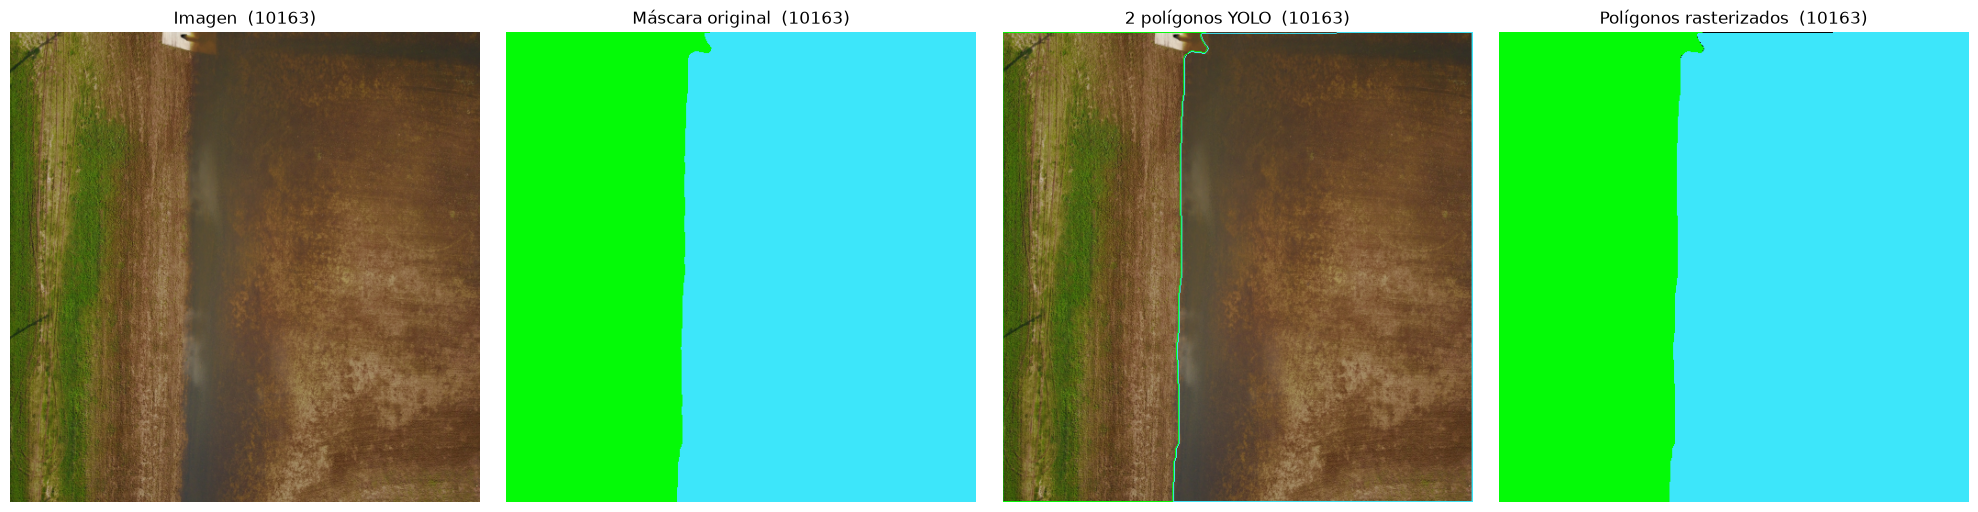

In [10]:
# Una imagen de test: máscara original frente a polígonos YOLO rasterizados.
stem = split_stems["test"][0]
img = cv2.cvtColor(cv2.imread(str(CACHE / "image" / f"{stem}.png")), cv2.COLOR_BGR2RGB)
gt = cv2.imread(str(CACHE / "mask" / f"{stem}.png"), cv2.IMREAD_GRAYSCALE)
polys = leer_etiquetas(YOLO_DIR / "labels" / "test" / f"{stem}.txt")

contornos = img.copy()
for c, p, _ in polys:
    cv2.polylines(contornos, [np.round(p).astype(np.int32)], True, PALETA[c].tolist(), 1)

fig, ax = plt.subplots(1, 4, figsize=(20, 5))
for a, im, t in zip(ax, [img, colorear(gt), contornos, colorear(rasterizar(polys))],
                    ["Imagen", "Máscara original", f"{len(polys)} polígonos YOLO", "Polígonos rasterizados"]):
    a.imshow(im); a.set_title(f"{t}  ({stem})"); a.axis("off")
plt.tight_layout(); plt.show()

---
# 5. Entrenamiento

Se parte de `yolo11n-seg.pt` (preentrenado en COCO) y se entrena con los parámetros de la celda **P**.
Ultralytics elige el mejor checkpoint (`best.pt`) por su *fitness* en val, una combinación de mAP de
caja y de máscara. Los resultados se guardan en `runs/yolo/yolo11n-seg-full/`.

Con `workers = 4` la carga y la augmentación (mosaico incluido) van en paralelo. Con 317 imágenes
cada época tardaba unos 3 s (19 s con `workers = 0`); con 1.387 hay que contar unas 4-5 veces más,
más la validación sobre 434 imágenes. `patience = 50` corta el entrenamiento cuando el *fitness*
de val lleva 50 épocas sin mejorar. Ultralytics define su dataset en un módulo
importable, así que los workers por *spawn* de Windows funcionan también dentro de Jupyter. Si en
otra máquina se colgara, `workers = 0` es la alternativa segura.

In [11]:
from ultralytics import YOLO

RUN_DIR = PROJECT / "runs" / "yolo" / "yolo11n-seg-full"
BEST_PT = RUN_DIR / "weights" / "best.pt"

if ENTRENAR:
    model = YOLO(CONFIG["modelo_base"])
    model.train(
        data=str(DATA_YAML),
        imgsz=CONFIG["img_size"],
        epochs=CONFIG["epochs"],
        patience=CONFIG["patience"],
        batch=CONFIG["batch"],
        workers=CONFIG["workers"],
        optimizer=CONFIG["optimizer"],
        fliplr=CONFIG["fliplr"],
        flipud=CONFIG["flipud"],
        mosaic=CONFIG["mosaic"],
        overlap_mask=CONFIG["overlap_mask"],
        seed=CONFIG["seed"],
        deterministic=CONFIG["deterministic"],
        project=str(RUN_DIR.parent),
        name=RUN_DIR.name,
        exist_ok=True,
        device=0,
        verbose=False,
    )

assert BEST_PT.exists(), f"No existe {BEST_PT}: entrena con ENTRENAR = True"
model = YOLO(str(BEST_PT))
print("Checkpoint:", BEST_PT)

New https://pypi.org/project/ultralytics/8.4.191 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.177  Python-3.12.10 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\data\yolo512_full\floodnet.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=300, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, m

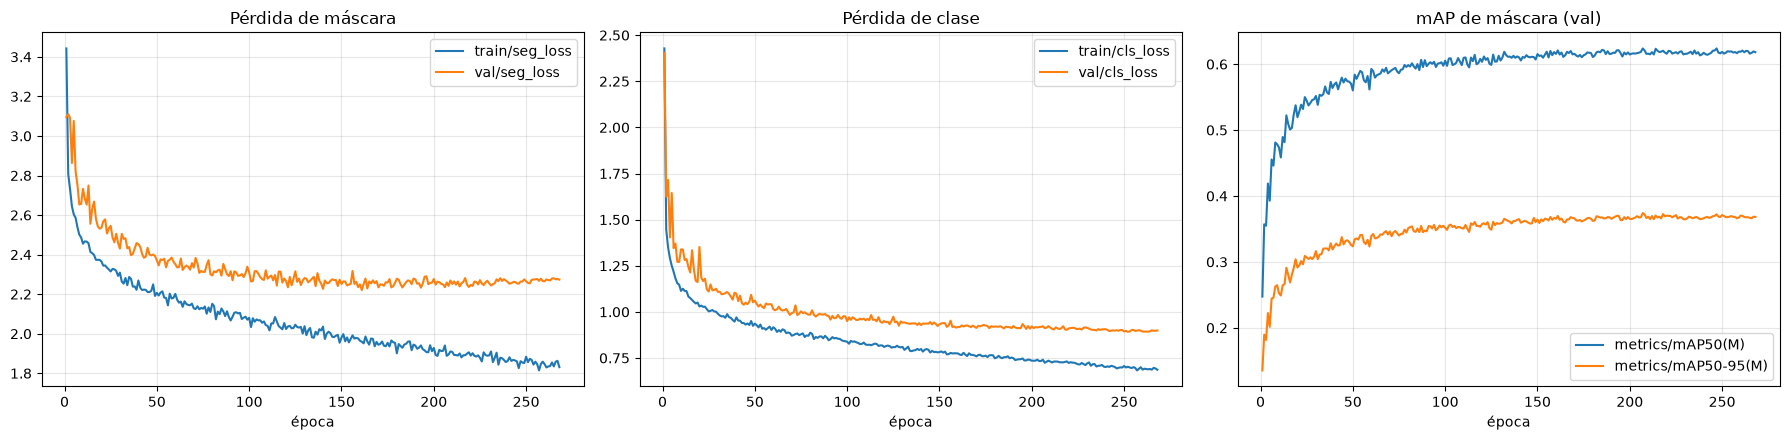

Épocas ejecutadas: 268


In [12]:
hist = pd.read_csv(RUN_DIR / "results.csv")
hist.columns = [c.strip() for c in hist.columns]

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for col in ("train/seg_loss", "val/seg_loss"):
    ax[0].plot(hist["epoch"], hist[col], label=col)
for col in ("train/cls_loss", "val/cls_loss"):
    ax[1].plot(hist["epoch"], hist[col], label=col)
for col in ("metrics/mAP50(M)", "metrics/mAP50-95(M)"):
    ax[2].plot(hist["epoch"], hist[col], label=col)
for a, t in zip(ax, ["Pérdida de máscara", "Pérdida de clase", "mAP de máscara (val)"]):
    a.set_title(t); a.set_xlabel("época"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"Épocas ejecutadas: {len(hist)}")

### 5.1 Matriz de confusión de Ultralytics

Ultralytics la calcula sobre val al final del entrenamiento. Es una matriz **de instancias**, no de
píxeles: empareja cada predicción (conf > 0.25) con un objeto real de caja con IoU > 0.45. Añade una
fila y una columna `background`:

- **Columna `background`**: predicciones que no se emparejan con ningún objeto real (falsos positivos).
- **Fila `background`**: objetos reales que el modelo no detecta (falsos negativos).

Como *Background* no es una clase de YOLO, ese `background` es el mismo concepto que el de FloodNet: lo
que no es ninguna instancia. No es comparable con el mIoU de la sección 6, que se mide por píxel.


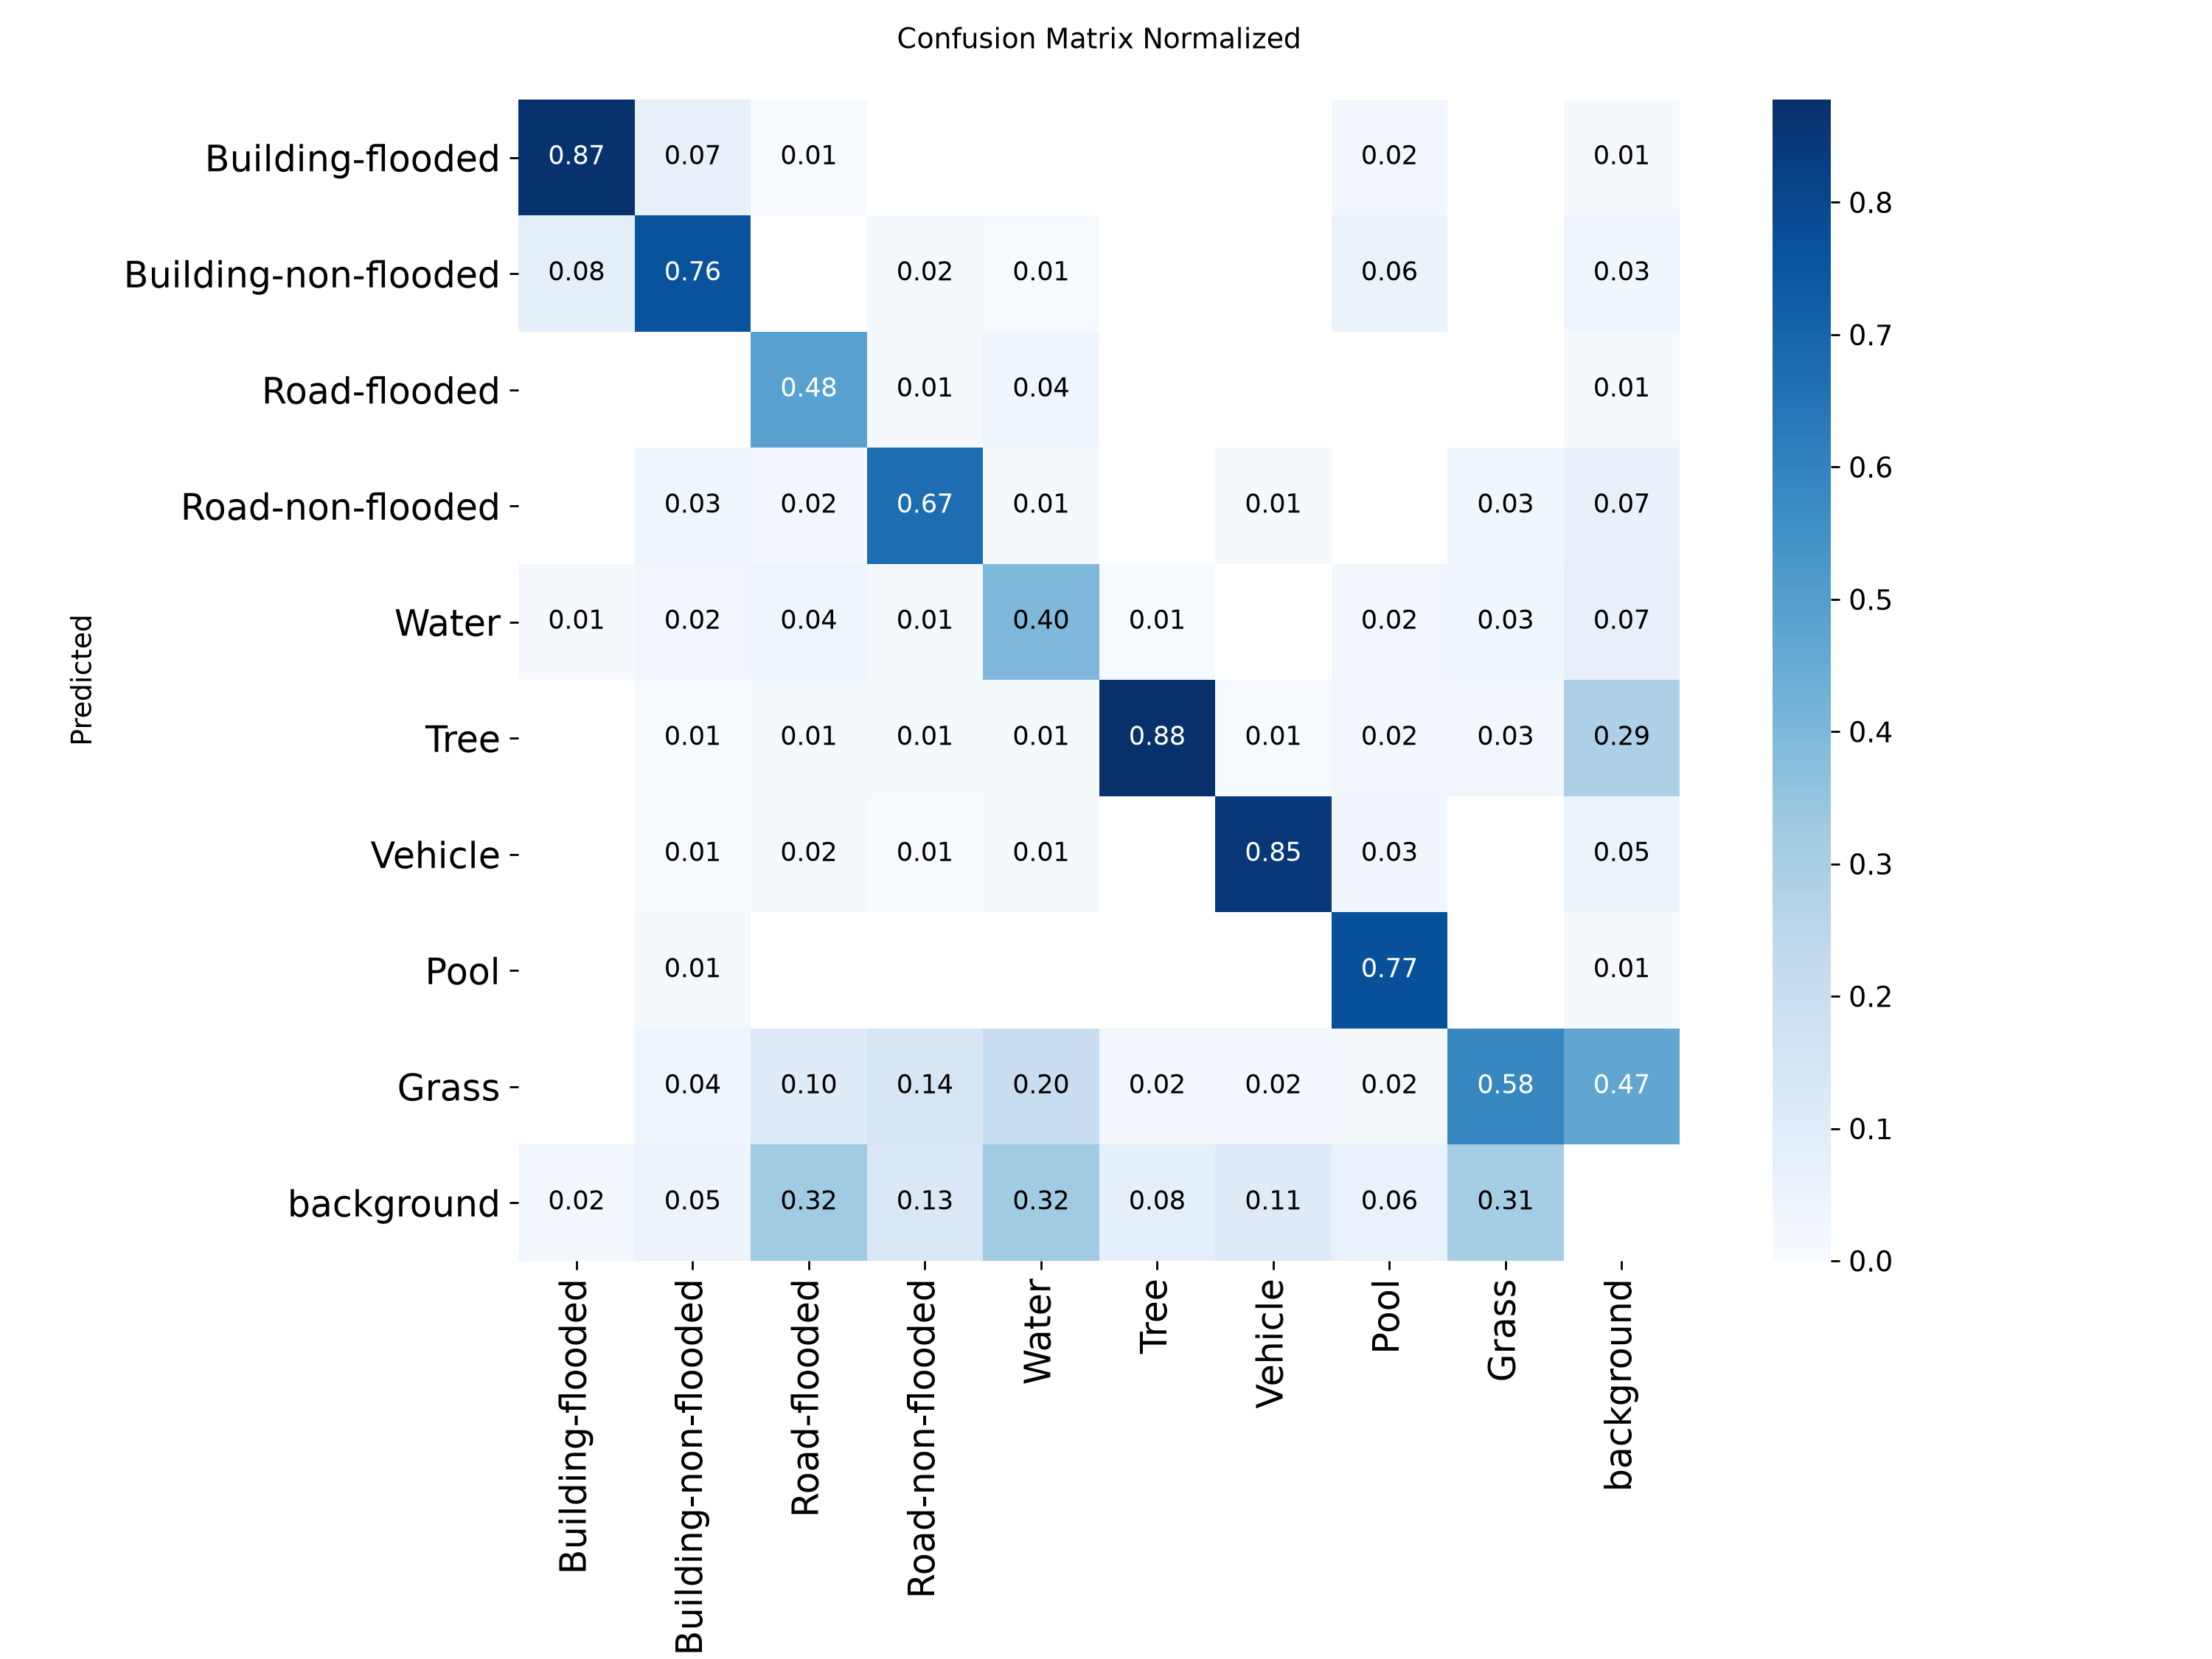

In [13]:
from IPython.display import Image, display

display(Image(filename=str(RUN_DIR / "confusion_matrix_normalized.png"), width=900))


---
# 6. Evaluación

### 6.1 mAP de instancias (métrica nativa de YOLO)

Es la métrica para la que YOLO está optimizado, calculada sobre las "instancias" artificiales de la
sección 3. **No es comparable con el mIoU del U-Net.** Se informa solo como referencia.

In [14]:
val_test = model.val(data=str(DATA_YAML), split="test", imgsz=SIZE, batch=CONFIG["batch"],
                     device=0, plots=False, verbose=False)
map_test = {
    "box_mAP50": float(val_test.box.map50), "box_mAP50_95": float(val_test.box.map),
    "mask_mAP50": float(val_test.seg.map50), "mask_mAP50_95": float(val_test.seg.map),
}
print(json.dumps(map_test, indent=2))
pd.DataFrame({"Clase": [YOLO_NAMES[i] for i in val_test.seg.ap_class_index],
              "mask AP50-95": np.round(val_test.seg.maps[val_test.seg.ap_class_index], 3)})

Ultralytics 8.4.177  Python-3.12.10 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
YOLO11n-seg summary (fused): 114 layers, 2,851,411 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 77.4±18.6 MB/s, size: 512.6 KB)
val: Scanning C:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\data\yolo512_full\labels\test... 426 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 426/426 318.0it/s 1.3s0.1s
val: New cache created: C:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\data\yolo512_full\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 1.1s/it 28.6s0.1s
                   all        426       8857      0.726      0.599      0.624      0.425      0.726      0.587      0.605      0.358
Speed: 0.6ms preprocess, 3.1ms inference, 0.0ms loss, 1.6ms postprocess per image
{
  "box_mAP50": 0.6243339842690778,
  "box_m

,Clase,mask AP50-95
0,Building-flooded,0.597
1,Building-non-flooded,0.516
2,Road-flooded,0.150
3,Road-non-flooded,0.374
4,Water,0.291
5,Tree,0.422
6,Vehicle,0.262
7,Pool,0.382
8,Grass,0.228


### 6.2 mIoU semántico: la comparación justa con el U-Net

Para cada imagen:

1. `predict` con `retina_masks=True`, que devuelve las máscaras a 512×512 en vez de a 128×128.
2. Las instancias se pintan **de mayor a menor área**, la misma regla que en entrenamiento, con la
   clase YOLO + 1 para volver al índice de FloodNet.
3. Los píxeles que no cubre ninguna instancia son *Background*.

El umbral de confianza importa: si es bajo aparecen más falsos positivos y si es alto quedan más
píxeles sin instancia, que pasan a *Background*.
Se elige **en val** entre los candidatos de `CONFIG` y se aplica **una sola vez** en test.

In [15]:
def mapa_semantico(r):
    # Resultado de Ultralytics -> mapa de etiquetas FloodNet (SIZE, SIZE); sin instancia = Background.
    lab = np.zeros((SIZE, SIZE), dtype=np.uint8)
    if r.masks is None or len(r.masks) == 0:
        return lab
    m = r.masks.data.cpu().numpy() > 0.5
    if m.shape[1:] != (SIZE, SIZE):
        m = np.stack([cv2.resize(x.astype(np.uint8), (SIZE, SIZE),
                                 interpolation=cv2.INTER_NEAREST) > 0 for x in m])
    cls = r.boxes.cls.cpu().numpy().astype(int) + 1     # clase YOLO -> clase FloodNet
    for i in np.argsort(-m.sum(axis=(1, 2)), kind="stable"):
        lab[m[i]] = cls[i]
    return lab

def predecir(modelo, ruta, conf):
    r = modelo.predict(ruta, imgsz=SIZE, conf=conf, iou=CONFIG["iou_nms"], max_det=CONFIG["max_det"],
                       retina_masks=True, device=0, verbose=False)[0]
    return mapa_semantico(r)

def evaluar_semantico(modelo, imgs, msks, conf, desc=""):
    # Devuelve la métrica de todo el conjunto y la matriz de confusión de cada imagen.
    met, por_imagen = SegMetrics(NUM_CLASSES), {}
    for ip, mp in tqdm(list(zip(imgs, msks)), desc=desc, leave=False):
        m = SegMetrics(NUM_CLASSES)
        m.update_labels(predecir(modelo, ip, conf), cv2.imread(mp, cv2.IMREAD_GRAYSCALE))
        met.conf += m.conf
        por_imagen[Path(ip).stem] = m.conf
    return met, por_imagen

barrido = []
for conf in CONFIG["conf_candidatos"]:
    met, _ = evaluar_semantico(model, val_imgs, val_masks, conf, desc=f"val conf={conf}")
    miou, mdice, acc = met.summary()
    barrido.append({"conf": conf, "mIoU": miou, "mIoU_sin_bg": met.summary(ignore=(0,))[0],
                    "PixAcc": acc, "sin instancia %": 100 * met.sin_instancia()})
barrido = pd.DataFrame(barrido).round(4)
CONF = float(barrido.loc[barrido["mIoU"].idxmax(), "conf"])
print("Umbral elegido en val:", CONF)
barrido


val conf=0.05:   0%|          | 0/434 [00:00<?, ?it/s]

val conf=0.1:   0%|          | 0/434 [00:00<?, ?it/s]

val conf=0.25:   0%|          | 0/434 [00:00<?, ?it/s]

val conf=0.4:   0%|          | 0/434 [00:00<?, ?it/s]

Umbral elegido en val: 0.25


,conf,mIoU,mIoU_sin_bg,PixAcc,sin instancia %
0,0.05,0.6635,0.7248,0.8867,1.5759
1,0.10,0.6823,0.7384,0.8915,2.3273
2,0.25,0.6950,0.7558,0.8879,3.7322
3,0.40,0.6869,0.7488,0.8701,6.2662


In [16]:
met_test, conf_test_img = evaluar_semantico(model, test_imgs, test_masks, CONF, desc="test")
res_test, tabla_test = informe(met_test, f"TEST ({len(test_imgs)} imágenes) — YOLO11n-seg, conf={CONF}")
tabla_test.assign(**{"Techo conversión IoU": tabla_techo["IoU"]})

test:   0%|          | 0/426 [00:00<?, ?it/s]

== TEST (426 imágenes) — YOLO11n-seg, conf=0.25 ==
  mIoU  : 0.6607   (sin Background: 0.7302)
  Dice  : 0.7632   (sin Background: 0.8403)
  PixAcc: 0.8832
  Píxeles sin instancia (→ Background): 3.10 %


,Clase,Dice,IoU,Techo conversión IoU
0,Background,0.069,0.036,0.921
1,Building-flooded,0.826,0.704,0.983
2,Building-non-flooded,0.870,0.769,0.989
3,Road-flooded,0.785,0.646,0.989
4,Road-non-flooded,0.902,0.821,0.987
5,Water,0.835,0.716,0.995
6,Tree,0.909,0.834,0.990
7,Vehicle,0.711,0.552,0.944
8,Pool,0.796,0.661,0.974
9,Grass,0.930,0.870,0.995


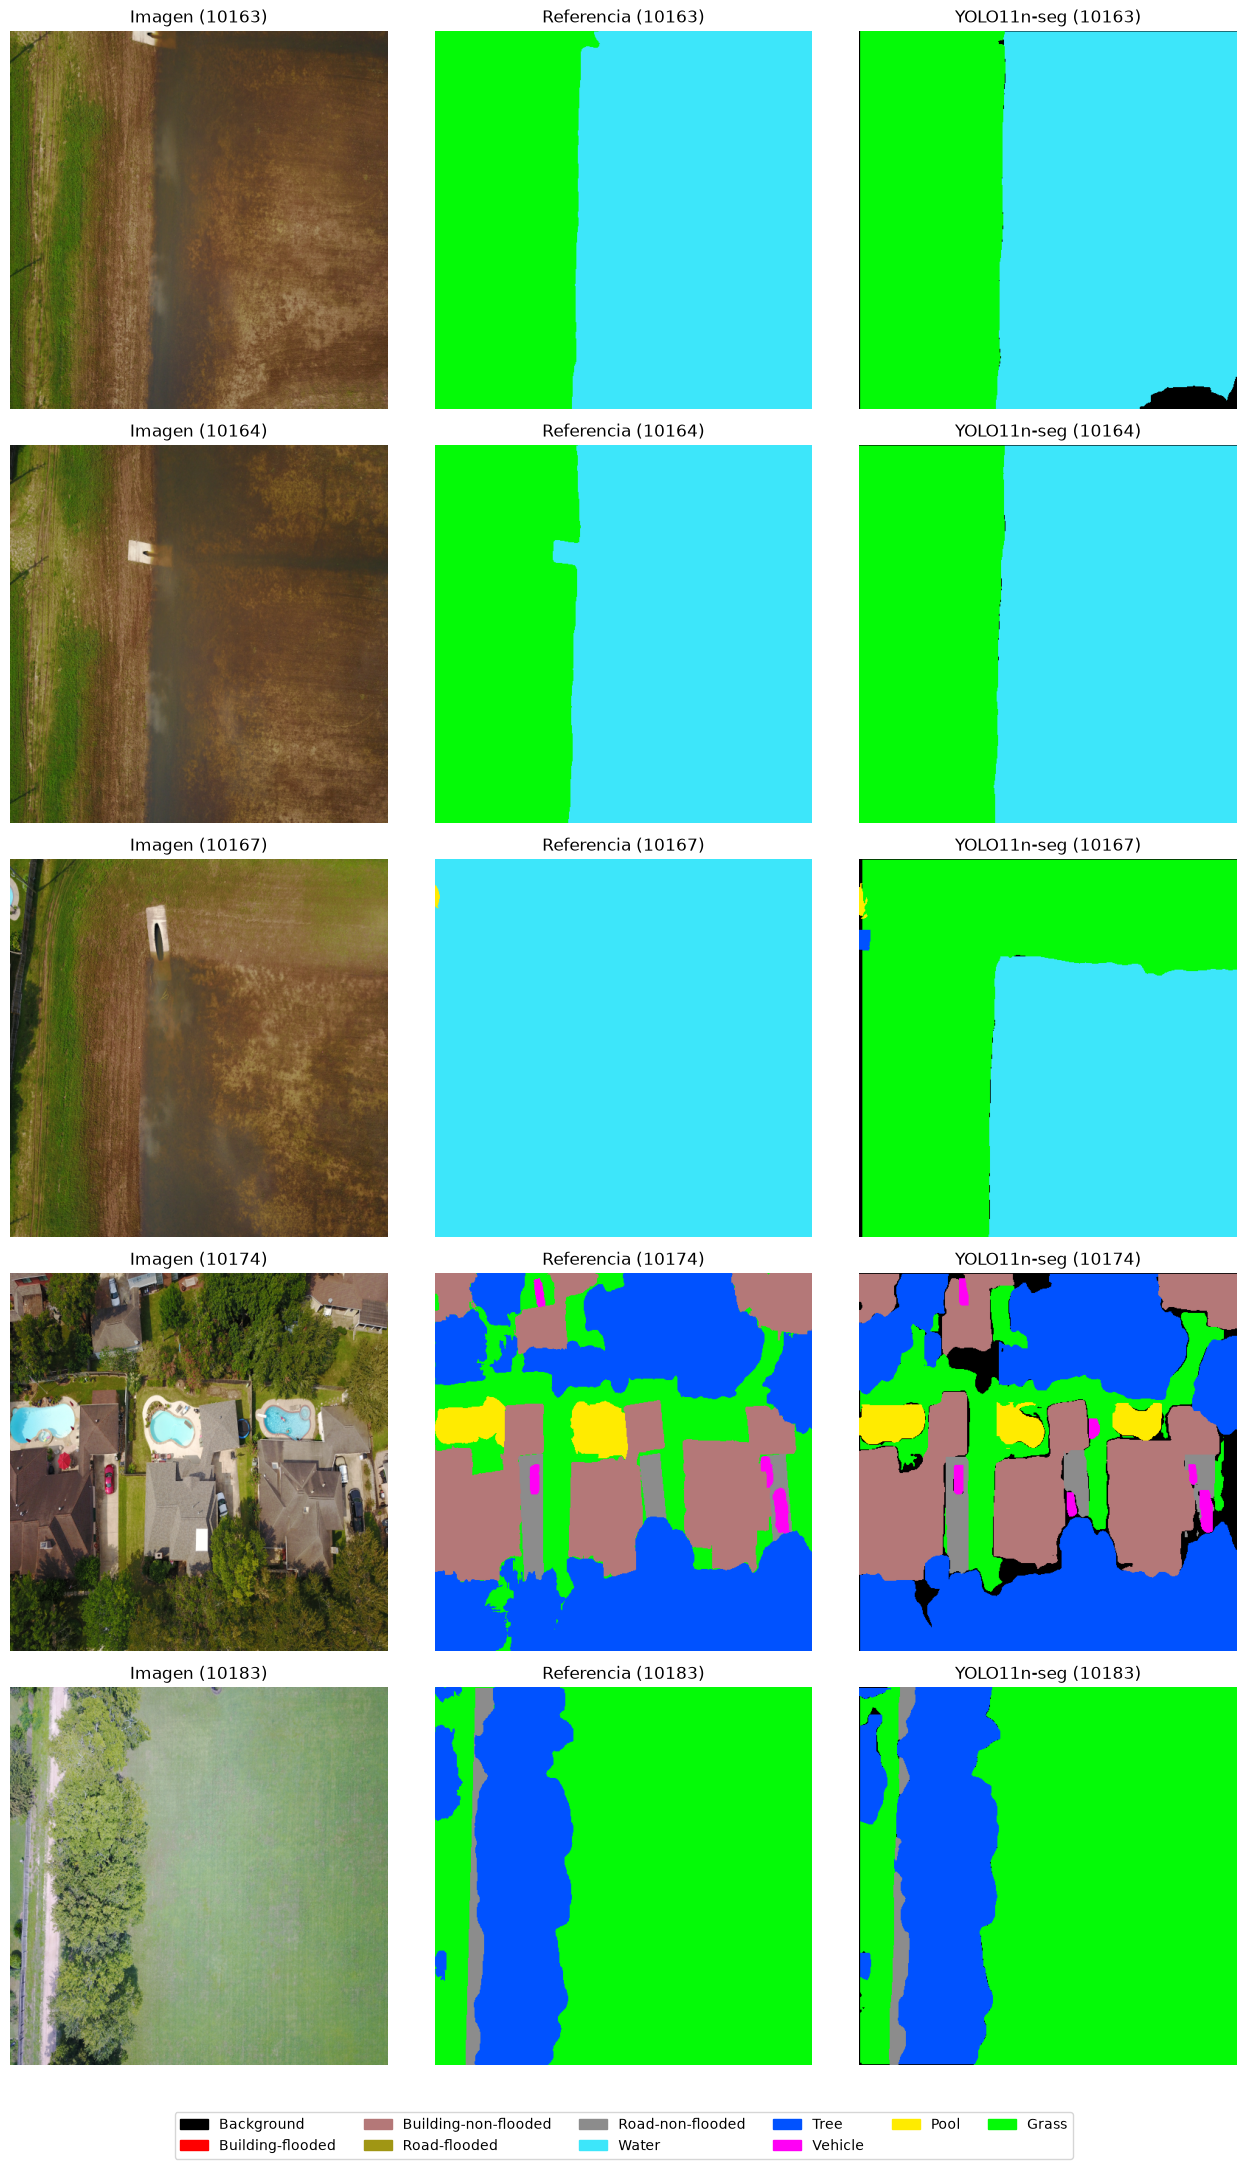

In [17]:
# Ejemplos de test: imagen, referencia y predicción.
muestras = test_imgs[:5]
fig, ax = plt.subplots(len(muestras), 3, figsize=(13, 4.3 * len(muestras)))
for i, ip in enumerate(muestras):
    stem = Path(ip).stem
    img = cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB)
    gt = cv2.imread(test_masks[i], cv2.IMREAD_GRAYSCALE)
    pred = predecir(model, ip, CONF)
    for a, im, t in zip(ax[i], [img, colorear(gt), colorear(pred)], ["Imagen", "Referencia", "YOLO11n-seg"]):
        a.imshow(im); a.set_title(f"{t} ({stem})"); a.axis("off")

from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=PALETA[c] / 255, label=n) for c, n in enumerate(class_names)],
           loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

---
# 7. Exportación a ONNX y verificación

Se exporta `best.pt` con entrada fija `1×3×512×512` en FP32 y se copia a
`models/yolo11n_seg_floodnet_full.onnx`.

**Qué hay dentro del grafo y qué no.** Este punto importa para medir el rendimiento:

| | ¿En el ONNX? |
|---|---|
| Backbone, neck y cabeza | Sí |
| `output0` 1×45×5376: caja xywh (4) + puntuación por clase (9, sin *Background*) + coeficientes de máscara (32) | Sí |
| `output1` 1×32×128×128: prototipos de máscara | Sí |
| NMS, ensamblado de máscaras (coeficientes × prototipos, sigmoide, recorte, reescalado) | **No** |
| Repintado a mapa semántico (clase YOLO + 1; sin instancia = *Background*) | **No** |

Un benchmark que cronometre solo `session.run()` dejaría fuera una parte del trabajo que el
modelo semántico sí hace dentro del grafo, así que el post-proceso tiene que cronometrarse aparte.

**Preprocesado esperado**: RGB (no BGR), `float32` en [0, 1], NCHW. Como las imágenes ya miden 512×512
no hace falta *letterbox*.

La verificación carga el `.onnx` con Ultralytics, que lo ejecuta con ONNX Runtime, y repite la
evaluación semántica de test. El mIoU debe coincidir con el de PyTorch.

In [18]:
import onnx

ONNX_PATH = PROJECT / CONFIG["onnx_path"]
exportado = model.export(format="onnx", imgsz=SIZE, opset=CONFIG["onnx_opset"], simplify=True,
                         dynamic=False, half=False, device=0)
shutil.copy2(exportado, ONNX_PATH)

grafo = onnx.load(str(ONNX_PATH))
onnx.checker.check_model(grafo)
def _forma(v):
    return [d.dim_value or d.dim_param for d in v.type.tensor_type.shape.dim]
io_onnx = {"inputs":  {v.name: _forma(v) for v in grafo.graph.input},
           "outputs": {v.name: _forma(v) for v in grafo.graph.output}}
print(ONNX_PATH, f"({ONNX_PATH.stat().st_size / 2**20:.1f} MB)")
print(json.dumps(io_onnx, indent=2))

WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.177  Python-3.12.10 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
YOLO11n-seg summary (fused): 114 layers, 2,851,411 parameters, 0 gradients, 6.2 GFLOPs

PyTorch: starting from 'c:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\runs\yolo\yolo11n-seg-full\weights\best.pt' with input shape (1, 3, 512, 512) BCHW and output shape(s) ((1, 45, 5376), (1, 32, 128, 128)) (5.8 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success  3.8s, saved as 'c:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\runs\yolo\yolo11n-seg-full\weights\best.onnx' (11.1 MB)

Export complete (4.0s)
Results saved to C:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\runs\yolo\yolo11n-seg-full\weights\best.onnx
Predict:         yolo predict task=segment model=c:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\runs\yolo\yolo11n-seg-full\we

In [19]:
import onnxruntime as ort

model_onnx = YOLO(str(ONNX_PATH), task="segment")
met_onnx, _ = evaluar_semantico(model_onnx, test_imgs, test_masks, CONF, desc="test ONNX")
res_onnx, _ = informe(met_onnx, "TEST — ONNX Runtime")
print("\nProveedores ONNX Runtime disponibles:", ort.get_available_providers())

dif = abs(res_onnx["mIoU"] - res_test["mIoU"])
print(f"|mIoU ONNX - mIoU PyTorch| = {dif:.5f}")
assert dif < 0.005, "El ONNX no reproduce al modelo de PyTorch"

test ONNX:   0%|          | 0/426 [00:00<?, ?it/s]

Loading c:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\models\yolo11n_seg_floodnet_full.onnx for ONNX Runtime inference...


Using ONNX Runtime 1.24.4 with CUDAExecutionProvider
== TEST — ONNX Runtime ==
  mIoU  : 0.6608   (sin Background: 0.7302)
  Dice  : 0.7632   (sin Background: 0.8403)
  PixAcc: 0.8832
  Píxeles sin instancia (→ Background): 3.10 %

Proveedores ONNX Runtime disponibles: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
|mIoU ONNX - mIoU PyTorch| = 0.00001


### 7.1 Registro de parámetros y resultados

Todo lo necesario para reproducir y evaluar el modelo sale en un único JSON: configuración, lista
exacta de imágenes de cada partición, contrato de entrada/salida del ONNX y cifras obtenidas.

In [20]:
registro = {
    "config": CONFIG,
    "conf_elegido_en_val": CONF,
    "clases": class_names,
    "clases_yolo": YOLO_NAMES,
    "split_stems": split_stems,
    "onnx": {
        "path": CONFIG["onnx_path"],
        **io_onnx,
        "preprocesado": "RGB, float32 en [0,1], NCHW 1x3x512x512; imagen ya a 512, sin letterbox",
        "postprocesado_fuera_del_grafo": [
            f"filtrado por confianza (conf={CONF}) y NMS (iou={CONFIG['iou_nms']}, max_det={CONFIG['max_det']})",
            "máscara = sigmoid(coeficientes · prototipos 32x128x128), recorte a la caja, reescalado a 512, umbral 0.5",
            CONFIG["regla_repintado"],
        ],
    },
    "resultados": {
        "techo_conversion": res_techo,
        "val_barrido_conf": barrido.to_dict(orient="records"),
        "test_pytorch": res_test,
        "test_onnx": res_onnx,
        "test_por_clase": tabla_test.to_dict(orient="records"),
        "test_instancias": map_test,
        "epocas_ejecutadas": int(len(hist)),
    },
    "versiones": {"ultralytics": ultralytics.__version__, "torch": torch.__version__,
                  "onnx": onnx.__version__, "onnxruntime": ort.__version__},
}
(PROJECT / CONFIG["config_json"]).write_text(json.dumps(registro, indent=2, ensure_ascii=False, default=float),
                                              encoding="utf-8")
print("Guardado:", CONFIG["config_json"])

Guardado: models/yolo11n_seg_floodnet_full_config.json


### 7.2 Libro de resultados

Actualiza todo lo que es de YOLO en `floodnet_resultados.xlsx`, con las métricas de test de esta
ejecución:

| Hoja | Qué se reescribe |
|---|---|
| YOLO11n-seg | IoU, precisión y recall por clase de cada imagen, pixel accuracy y % sin instancia |
| Resumen | Columna de YOLO: métricas globales, entrenamiento y comprobación |
| Por clase | IoU, Dice, precisión y recall de YOLO |
| Distribución de clases | ρ y p de Spearman de YOLO (la IoU está enlazada a «Por clase») |
| Parámetros, Léeme | Textos de YOLO que dependen de esta ejecución |

Las celdas vacías siguen las definiciones de la hoja Léeme: IoU vacía si la clase no está ni en la
referencia ni en la predicción, precisión vacía si no se predice y recall vacío si no está en la
referencia. Las fórmulas del libro se recalculan al abrirlo en Excel.


In [21]:
import math

import openpyxl
from scipy.stats import spearmanr

EXCEL  = PROJECT / "floodnet_resultados.xlsx"
MODELO = "YOLO11n-seg"

def metricas_imagen(conf):
    # IoU, precisión y recall por clase (NaN = celda vacía), pixel accuracy y % sin instancia.
    tp = np.diag(conf).astype(np.float64)
    reales, predichos = conf.sum(axis=1), conf.sum(axis=0)
    union = reales + predichos - tp
    with np.errstate(invalid="ignore", divide="ignore"):
        iou  = np.where(union > 0, tp / union, np.nan)
        prec = np.where(predichos > 0, tp / predichos, np.nan)
        rec  = np.where(reales > 0, tp / reales, np.nan)
    return iou, prec, rec, tp.sum() / conf.sum(), predichos[0] / conf.sum()

def celda(v):
    return None if np.isnan(v) else float(v)

def escribir(ws, r, c, v):
    ws.cell(r, c).value = v        # ws.cell(r, c, None) no borra la celda

def filas_por_etiqueta(ws, col=1):
    return {ws.cell(r, col).value: r for r in range(1, ws.max_row + 1)}

iou_g, prec_g, rec_g, _, _ = metricas_imagen(met_test.conf)
dice_g = met_test.dice_per_class()

# Datos del entrenamiento: la mejor época es la fila de results.csv con las métricas guardadas en best.pt.
ck = torch.load(BEST_PT, map_location="cpu", weights_only=False)["train_metrics"]
mejor_epoca = int(hist.loc[(hist["metrics/mAP50-95(M)"] - ck["metrics/mAP50-95(M)"]).abs().idxmin(), "epoch"])
horas = float(hist["time"].iloc[-1]) / 3600
fusionado = YOLO(str(BEST_PT))
fusionado.fuse()                       # BatchNorm plegada en las convoluciones, como en el ONNX
n_params = sum(p.numel() for p in fusionado.model.parameters())
# Regla de optimizer="auto" en Ultralytics (BaseTrainer.build_optimizer): AdamW con lr = 0.002·5/(4 + nc)
# si el entrenamiento tiene <= 10.000 iteraciones (lotes de nbs = 64).
assert math.ceil(len(train_imgs) / max(CONFIG["batch"], 64)) * CONFIG["epochs"] <= 10_000
lr_auto = round(0.002 * 5 / (4 + len(YOLO_NAMES)), 6)

wb = openpyxl.load_workbook(EXCEL)

# ---- Hoja por imagen: B:K IoU, L:U precisión, V:AE recall, AI pixel accuracy, AJ % sin instancia ----
ws = wb[MODELO]
assert ws["B4"].value == "IoU\nBackground" and ws["AI4"].value == "Pixel accuracy"
ws["AJ4"] = "% píxeles sin instancia"
filas = {ws.cell(r, 1).value: r for r in range(5, ws.max_row + 1)}
assert sorted(filas) == sorted(f"{s}.jpg" for s in conf_test_img), "Las imágenes de la hoja no son las de test"
espurias, omitidas = [], []
for stem, conf in conf_test_img.items():
    r = filas[f"{stem}.jpg"]
    iou, prec, rec, acc, sin_inst = metricas_imagen(conf)
    for k, v in enumerate([*iou, *prec, *rec]):
        escribir(ws, r, 2 + k, celda(v))
    escribir(ws, r, 35, float(acc))
    escribir(ws, r, 36, float(sin_inst))
    reales, predichos = conf.sum(axis=1), conf.sum(axis=0)
    espurias.append(int(((predichos > 0) & (reales == 0)).sum()))
    omitidas.append(int(((reales > 0) & (predichos == 0)).sum()))

# ---- Resumen: columna D ----
ws = wb["Resumen"]
f = filas_por_etiqueta(ws)
fila_sin = f.get("% píxeles sin predicción", f.get("% píxeles sin instancia (solo YOLO)"))
escribir(ws, fila_sin, 1, "% píxeles sin instancia (solo YOLO)")
for col in (2, 3, 5):
    escribir(ws, fila_sin, col, None)
f["% píxeles sin instancia (solo YOLO)"] = fila_sin
for etiqueta, valor in [
    ("mIoU (10 clases)", res_test["mIoU"]),
    ("mIoU (sin Background)", res_test["mIoU_sin_bg"]),
    ("Dice medio (10 clases)", res_test["Dice"]),
    ("Dice medio (sin Background)", res_test["Dice_sin_bg"]),
    ("Precisión (media por clase)", float(np.nanmean(prec_g))),
    ("Recall (media por clase)", float(np.nanmean(rec_g))),
    ("Pixel accuracy", res_test["PixAcc"]),
    ("% píxeles sin instancia (solo YOLO)", res_test["sin_instancia"]),
    ("Parámetros", n_params),
    ("Épocas ejecutadas", int(len(hist))),
    ("Mejor época (val)", mejor_epoca),
    ("Tiempo de entrenamiento (h, RTX 4060 Laptop)", round(horas, 3)),
    ("mIoU reportado por el cuaderno", res_test["mIoU"]),
]:
    escribir(ws, f[etiqueta], 4, valor)

# ---- Por clase: D IoU, G Dice, J precisión, M recall ----
ws = wb["Por clase"]
assert [ws.cell(4, c).value for c in (4, 7, 10, 13)] == [MODELO] * 4
f = filas_por_etiqueta(ws)
for c, nombre in enumerate(class_names):
    for col, v in ((4, iou_g[c]), (7, dice_g[c]), (10, prec_g[c]), (13, rec_g[c])):
        escribir(ws, f[nombre], col, celda(v))

# ---- Distribución de clases: ρ y p de YOLO en la tabla de Spearman ----
ws = wb["Distribución de clases"]
assert (ws["B4"].value, ws["C5"].value, ws["H5"].value, ws["J5"].value) == ("Píxeles", "% train", "% train", "Media")
VARIABLES = {"% píxeles train": 3, "% imágenes train": 8, "% medio cuando aparece": 10}
dist = pd.DataFrame([{"Clase": ws.cell(r, 1).value, **{v: ws.cell(r, c).value for v, c in VARIABLES.items()}}
                     for r in range(6, 6 + NUM_CLASSES)])
dist["IoU"] = dist["Clase"].map(dict(zip(class_names, iou_g)))
assert dist["IoU"].notna().all()
f_cab = next(r for r in range(1, ws.max_row + 1) if ws.cell(r, 1).value == "Variable")
cols = {ws.cell(f_cab, c).value: c for c in range(1, ws.max_column + 1)}
for r in range(f_cab + 1, f_cab + 1 + 2 * len(VARIABLES)):
    var, clases = ws.cell(r, 1).value, ws.cell(r, 2).value
    d = dist if clases == "10 clases" else dist[dist["Clase"] != "Background"]
    s = spearmanr(d[var], d["IoU"])
    escribir(ws, r, cols[f"ρ {MODELO}"], float(s.statistic))
    escribir(ws, r, cols[f"p {MODELO}"], float(s.pvalue))

# ---- Parámetros: columna D ----
ws = wb["Parámetros"]
f = filas_por_etiqueta(ws)
techo = f"{res_techo['mIoU']:.3f}".replace(".", ",")
for etiqueta, texto in [
    ("Arquitectura", "YOLO11n-seg (Ultralytics), segmentación de instancias de 9 clases (Background = sin instancia)"),
    ("Parámetros", f"{n_params:,}".replace(",", ".")),
    ("Épocas", f"{CONFIG['epochs']} máx. ({len(hist)} ejecutadas"
               f"{', early stopping' if len(hist) < CONFIG['epochs'] else ''})"),
    ("Optimizador", f"auto → AdamW, lr {lr_auto}, momentum 0.9"),
    ("Post-proceso", f"conf {CONF} (elegido en val), NMS iou {CONFIG['iou_nms']}, max_det {CONFIG['max_det']}, "
                     "repintado de mayor a menor área; sin instancia = Background"),
    ("Conversión de máscaras", f"Polígonos de las 9 clases sin Background, con los huecos de Background abiertos: "
                               f"área mínima {MIN_AREA} px, ε {EPS} px; techo mIoU {techo}"),
]:
    escribir(ws, f[etiqueta], 4, texto)

# ---- Léeme ----
ws = wb["Léeme"]
f = filas_por_etiqueta(ws)
r = f.get("% píxeles sin predicción", f.get("% píxeles sin instancia"))
escribir(ws, r, 1, "% píxeles sin instancia")
escribir(ws, r, 2, "Solo YOLO: píxeles que ninguna instancia cubre. YOLO no tiene la clase Background y se los "
              "asigna a ella: si su clase real es otra, son un FN de esa clase y un FP de Background.")
r = f["Inferencia"]
conf_txt = f"{CONF:g}".replace(".", ",")
texto, n = re.subn(r"y YOLO con best\.pt, conf [\d,]+( \(en GPU, sección 7\.2 de su cuaderno\))?\.",
                   f"y YOLO con best.pt, conf {conf_txt} (en GPU, sección 7.2 de su cuaderno).",
                   ws.cell(r, 2).value)
assert n == 1, "No encuentro la frase de YOLO en Léeme › Inferencia"
escribir(ws, r, 2, texto)

wb.calculation.fullCalcOnLoad = True   # openpyxl no guarda resultados de fórmulas: que Excel las recalcule
wb.save(EXCEL)
print(f"Actualizado {EXCEL.name}: {len(conf_test_img)} imágenes, mIoU {res_test['mIoU']:.4f}, "
      f"{n_params:,} parámetros, mejor época {mejor_epoca} de {len(hist)}, {horas:.2f} h")
print(f"Clases por imagen: {np.mean(espurias):.2f} espurias (predichas y ausentes en la referencia), "
      f"{np.mean(omitidas):.2f} omitidas. Léeme › «Clases espurias y media por imagen» cita estas cifras.")


YOLO11n-seg summary (fused): 114 layers, 2,851,411 parameters, 0 gradients, 9.7 GFLOPs
Actualizado floodnet_resultados.xlsx: 426 imágenes, mIoU 0.6607, 2,851,411 parámetros, mejor época 218 de 268, 2.07 h
Clases por imagen: 1.23 espurias (predichas y ausentes en la referencia), 0.14 omitidas. Léeme › «Clases espurias y media por imagen» cita estas cifras.


---
# Conclusiones

Cifras de esta ejecución sobre las 426 imágenes de test, con el umbral de confianza elegido en val
(0.25). Están también en `models/yolo11n_seg_floodnet_full_config.json`. Las del U-Net y DeepLabV3+
salen de sus cuadernos.

| | U-Net híbrido | DeepLabV3+ R50 | YOLO11n-seg |
|---|---:|---:|---:|
| mIoU test (10 clases) | **0.732** | 0.709 | 0.661 |
| mIoU test (sin *Background*) | **0.754** | 0.738 | 0.730 |
| Dice test (10 clases) | **0.841** | 0.823 | 0.763 |
| Pixel accuracy | **0.910** | 0.908 | 0.883 |
| Píxeles sin instancia (→ *Background*) | — | — | 3.1 % |
| TTA | sí (4 volteos) | no | no |
| Parámetros | — | 26.7 M | 2.9 M |
| Entrenamiento (RTX 4060 Laptop) | ~2 h 15 min, 30 épocas | 47 min, 40 épocas | 2.1 h, 268 épocas |

| Clase | IoU U-Net | IoU DeepLabV3+ | IoU YOLO11n-seg |
|---|---:|---:|---:|
| Grass | 0.884 | **0.885** | 0.870 |
| Road-non-flooded | **0.833** | 0.831 | 0.821 |
| Tree | 0.815 | 0.831 | **0.834** |
| Building-non-flooded | **0.806** | 0.800 | 0.769 |
| Water | **0.772** | 0.757 | 0.716 |
| Building-flooded | 0.707 | **0.711** | 0.704 |
| Pool | **0.680** | 0.647 | 0.661 |
| Road-flooded | **0.666** | 0.612 | 0.646 |
| Vehicle | **0.626** | 0.570 | 0.552 |
| Background | **0.526** | 0.450 | 0.036 |

Lecturas:

- **Quitar *Background* de las clases de YOLO cuesta 4.4 puntos de mIoU** (0.705 → 0.661 frente a
  la ejecución anterior, en la que era una clase más). Casi todo sale de *Background*, que pasa de
  0.394 a 0.036 de IoU, con precisión 0.06 y recall 0.08.
- **El modelo no aprende a dejar huecos.** Del *Background* real de test, el 49 % acaba pintado como
  *Water* y el 28 % como *Grass*: sin una instancia propia, esas zonas se las quedan las instancias
  vecinas. Y los píxeles que no cubre ninguna instancia (3.1 %) son sobre todo bordes entre instancias
  de *Grass*, *Tree* y *Road*: el 88 % está en imágenes que no tienen *Background*.
- **Sin *Background* también baja algo** (0.739 → 0.730). La mayor caída es *Water* (0.767 → 0.716),
  que se queda con buena parte del *Background* real: su precisión pasa de 0.89 a 0.83. Le siguen
  los dos *Building* (−2.3 y −2.5 puntos). *Road-non-flooded*, *Pool*, *Road-flooded* y *Tree* suben
  entre 0.3 y 1.2 puntos. Con una sola ejecución de cada variante, solo la caída de *Water* tiene una
  causa clara; el resto puede ser variación entre ejecuciones.
- **La métrica nativa de YOLO sube** (mAP50-95 de máscara en test 0.339 → 0.358), pero solo porque
  sale de la media *Background*, que tenía un AP de 0.140. La media de las otras nueve clases apenas
  cambia (0.361 → 0.358).
- **La matriz de confusión de Ultralytics tiene ahora un único `background`** (sección 5.1), que era
  el objetivo del cambio.
- **YOLO queda el último de los tres** en mIoU con y sin *Background*. Solo es el mejor en *Tree*.
  En la media por imagen cae a 0.575 (0.725 antes), porque predice *Background* en imágenes que no lo
  tienen: 1.23 clases espurias por imagen, frente a 0.51 del U-Net.
- **La conversión no es el cuello de botella**: los polígonos reconstruyen las máscaras con mIoU
  0.977 (0.921 en *Background*). Lo que se pierde frente a ese techo es cosa del modelo.
- **El entrenamiento se detuvo en la época 268** por *early stopping* (mejor época, la 218), tras
  2.1 horas.
- **El ONNX reproduce al modelo**: diferencia de mIoU de 0.00001 en test.

### Referencia: ejecución anterior, con *Background* como clase de YOLO

Mismo dataset, partición y parámetros, con 10 clases de YOLO. Los píxeles sin instancia quedaban
fuera de todas las clases (*void*) en vez de pasar a *Background*.

| | 10 clases | 9 clases (esta) |
|---|---:|---:|
| mIoU test (10 clases) | **0.705** | 0.661 |
| mIoU test (sin *Background*) | **0.739** | 0.730 |
| Dice test (10 clases) | **0.818** | 0.763 |
| Pixel accuracy | **0.890** | 0.883 |
| IoU *Background* | **0.394** | 0.036 |
| Píxeles sin instancia | 3.0 % (*void*) | 3.1 % (→ *Background*) |
| mAP50-95 de máscara en test | 0.339 | **0.358** |
| Techo de la conversión (mIoU) | **0.984** | 0.977 |
| Épocas (mejor) | 235 (185) | 268 (218) |

### Referencia: ejecución con el dataset reducido (317 / 40 / 41)

| | YOLO11n-seg | U-Net híbrido |
|---|---:|---:|
| mIoU test (10 clases) | 0.678 | 0.714 |
| mIoU test (sin *Background*) | 0.738 | 0.777 |
| Dice test (10 clases) | 0.783 | 0.809 |
| Pixel accuracy | 0.891 | 0.927 |
| Píxeles sin predicción | 4.7 % | 0 % |
| Techo de la conversión (mIoU) | 0.976 | — |
| Umbral de confianza elegido en val | 0.40 | — |